# DBSCAN

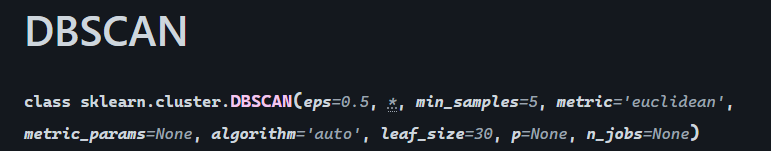

In [29]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import AgglomerativeClustering, KMeans, DBSCAN, HDBSCAN
from tqdm import tqdm
import seaborn as sns
import os
os.chdir("E:/Vishal_Adesh/CDAC/Machine Learning/Datasets")
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [4]:
df = pd.read_csv("milk.csv",index_col=0)
df.head()

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10


In [6]:
scaler = StandardScaler().set_output(transform='pandas')
scl_df = scaler.fit_transform(df)

In [8]:
dbs = DBSCAN(min_samples=2)
dbs.fit(scl_df)
dbs.labels_

array([ 0,  0,  0,  0, -1,  1,  1,  2, -1, -1,  2,  1,  0, -1,  1,  2, -1,
       -1, -1, -1,  3,  3, -1, -1, -1])

In [7]:
dbs = DBSCAN(eps=1, min_samples=2)
dbs.fit(scl_df)
dbs.labels_

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  1,
       -1, -1,  1,  2,  2,  2, -1, -1])

In [11]:
dbs = DBSCAN(eps=1.5, min_samples=2)
dbs.fit(scl_df)
dbs.labels_

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
       -1, -1,  0,  0,  0,  0,  1,  1])

In [16]:
inlier_obs = scl_df[dbs.labels_!=-1]
inlier_obs

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,0.948806,-1.009291,-0.903208,1.542217,-1.037554
ORANGUTAN,0.821407,-1.344603,-0.660619,1.040773,-1.259945
MONKEY,0.813445,-1.121062,-0.738247,1.263637,-1.381249
DONKEY,0.964731,-1.260775,-0.864394,1.152205,-0.936467
HIPPO,0.972694,-1.568145,-0.563583,0.149319,-1.542988
CAMEL,0.757707,-0.757806,-0.670322,0.372182,-0.309730
BISON,0.694008,-0.394551,-0.835283,0.873626,0.074400
BUFFALO,0.311810,-0.087181,-0.233662,0.316466,-0.168208
GUINEA PIG,0.295885,0.331959,-0.301587,-0.797852,-0.026687


In [18]:
inlier_labels = dbs.labels_[dbs.labels_!=-1]
inlier_labels

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1])

In [19]:
sc = silhouette_score(inlier_obs,inlier_labels)
sc

0.5528890106341011

In [24]:
eps = np.linspace(0.1,3,10)
minpts = [2,3,4,5]
score = []
for e in tqdm(eps):
    for p in minpts:
        dbs = DBSCAN(eps=e, min_samples=p)
        dbs.fit(scl_df)
        inlier_obs = scl_df[dbs.labels_!=-1]
        inlier_labels = dbs.labels_[dbs.labels_!=-1]
        if len(np.unique(inlier_labels)) > 1:
            sc = silhouette_score(inlier_obs,inlier_labels)
            score.append([e,p,sc])
df_score = pd.DataFrame(score,columns=["E","P","Score"])
df_score.sort_values("Score",ascending=False)
#Value Eror - Found array with 0 sample(s) (shape=(0, 5)) while a minimum of 1 is required.

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 71.16it/s]


,E,P,Score
0,0.422222,2,0.651894
5,1.388889,2,0.552889
1,0.422222,3,0.538518
8,2.355556,2,0.518685
7,2.033333,2,0.518685
6,1.711111,2,0.518685
9,2.677778,2,0.518685
4,1.066667,4,0.513335
2,0.744444,2,0.488035
3,0.744444,3,0.418695


# HDBSCAN

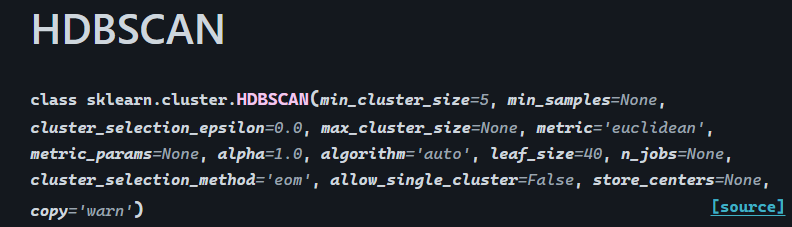

In [31]:
hdbs = HDBSCAN(min_cluster_size=2)
hdbs.fit(scl_df)
inlier_obs = scl_df[hdbs.labels_!=-1]
inlier_labels = hdbs.labels_[hdbs.labels_!=-1]
silhouette_score(inlier_obs,inlier_labels)

0.4901417725897087

In [48]:
hdbs = HDBSCAN(min_cluster_size=3)
hdbs.fit(scl_df)
inlier_obs = scl_df[hdbs.labels_!=-1]
inlier_labels = hdbs.labels_[hdbs.labels_!=-1]
silhouette_score(inlier_obs,inlier_labels)

0.5032777845817115

In [36]:
hdbs.labels_

array([ 2,  2,  2,  2, -1,  3, -1,  1, -1, -1,  1,  3,  2,  1,  3,  1,  0,
       -1, -1,  0,  0,  0,  0, -1, -1])

In [37]:
minpts = [2,3,4,5]
score = []
for p in tqdm(minpts):
        hdbs = HDBSCAN(min_cluster_size=p)
        hdbs.fit(scl_df)
        inlier_obs = scl_df[hdbs.labels_!=-1]
        inlier_labels = hdbs.labels_[hdbs.labels_!=-1]
        if len(np.unique(inlier_labels)) > 1:
            sc = silhouette_score(inlier_obs,inlier_labels)
            score.append([p,sc])
df_score = pd.DataFrame(score,columns=["P","Score"])
df_score.sort_values("Score",ascending=False)
#Value Eror - Found array with 0 sample(s) (shape=(0, 5)) while a minimum of 1 is required.

100%|███████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 173.94it/s]


,P,Score
1,3,0.503278
0,2,0.490142


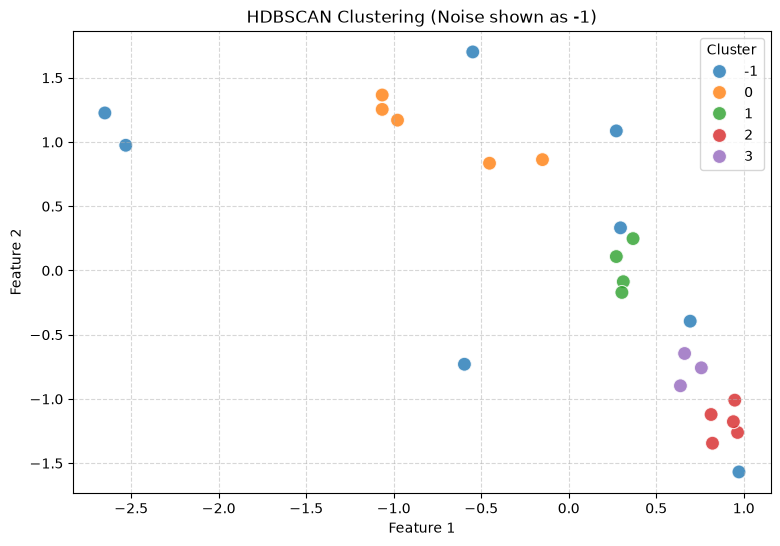

In [52]:
plot_df_hdb = scl_df.copy()
plot_df_hdb['Cluster'] = hdbs.labels_

# Plotting
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df_hdb, x=plot_df_hdb.columns[0], y=plot_df_hdb.columns[1], hue='Cluster', palette='tab10', legend='full',alpha=0.8,s=100
)
plt.title("HDBSCAN Clustering (Noise shown as -1)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

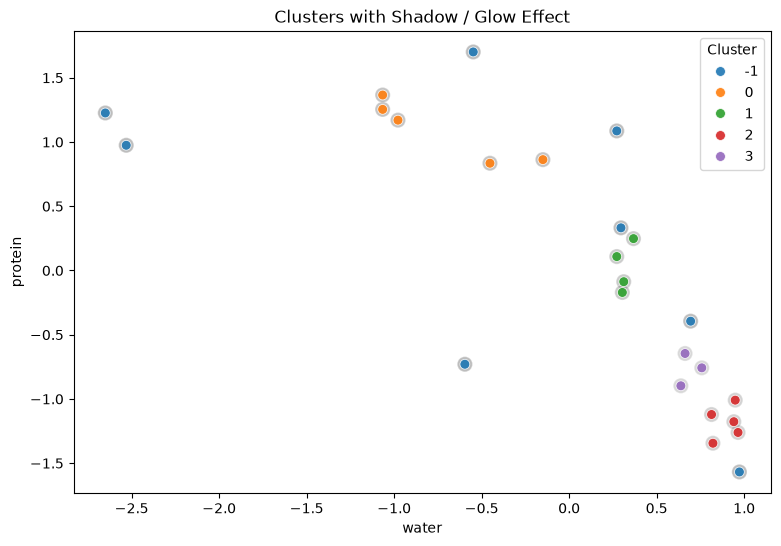

In [53]:
plt.figure(figsize=(9, 6))
# Layer 1: The "Shadow" / Glow effect (larger markers, lower alpha, dark color)
sns.scatterplot(data=plot_df_hdb, x=plot_df_hdb.columns[0], y=plot_df_hdb.columns[1], hue='Cluster',palette='dark:grey',s=120,             alpha=0.3,         legend=False
)
# Layer 2: The Main Core Points (smaller, sharp, colored by cluster)
sns.scatterplot(data=plot_df_hdb, x=plot_df_hdb.columns[0], y=plot_df_hdb.columns[1], hue='Cluster',palette='tab10',   s=50,            alpha=0.9,legend='full'
)
plt.title("Clusters with Shadow / Glow Effect")
plt.show